[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L1/BA_L1_trend/BA_L1_trend.ipynb)

# BA_L1_trend: Trend Lines on a Log Scale

*Quantlet of Lecture 1, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Log-linear trend regressions of Bitcoin transactions per day and Bitcoin market value, monthly means, November 2014 to October 2025, with Newey-West standard errors; the fitted trends give the annual growth rates shown on a log scale.

In [1]:
# packages that are not preinstalled on Colab
import importlib, subprocess, sys
for pkg in ['statsmodels']:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

In [2]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [3]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [4]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [5]:
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10, 'lines.linewidth': 1.5})   # as in the slide charts


def load_onchain(name):
    # daily on-chain series, one column per coin, as numbers (missing values are NaN)
    return onchain(name).apply(pd.to_numeric, errors='coerce')


def slide_legend(fig, bottom, ncol=3):
    # one legend for the whole figure, under the plots, as in the slides
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))

## Data and method

A compound annual growth rate (CAGR) uses two dates; a trend regression uses all of them:

$$\ln X_t = a + g\,t + u_t, \qquad t \text{ in years},$$

$g$ is the continuous growth rate and $e^{g} - 1$ the annual growth. The errors $u_t$ are strongly autocorrelated, so
standard errors are Newey–West (heteroskedasticity- and autocorrelation-consistent, HAC) with 12 lags; they do not
change the point estimates. Data: monthly means of Bitcoin transactions per day and Bitcoin market value, November
2014 to October 2025, with the 11 days of recording error removed. $R^2$ is the share of the variance of $\ln X_t$
explained by the trend.

The difference of the two growth rates is estimated directly, from $\ln(M_t/n_t) = a + (g_M - g_n)\,t + e_t$, because
the two series share the same months and their estimates are correlated.

**How to read the chart.** Monthly means (solid) and fitted trends (dashed) on a log scale: a constant growth rate is
a straight line. The market value moves around its trend in long waves.

In [6]:
import statsmodels.api as sm

tx, mc = load_onchain('transaction'), load_onchain('Mktcap')
mc.loc['2023-08-27':'2023-09-06', 'BTC'] = np.nan          # recording error
series = {'transactions per day': tx['BTC'], 'market value (USD million)': mc['BTC'] / 1e6}
trend = {}
for lab, s in series.items():
    mth = s.resample('ME').mean().dropna()                 # monthly means
    t = np.arange(len(mth)) / 12                            # time in years
    trend[lab] = (mth, sm.OLS(np.log(mth.values), sm.add_constant(t)).fit(cov_type='HAC', cov_kwds={'maxlags': 12}))

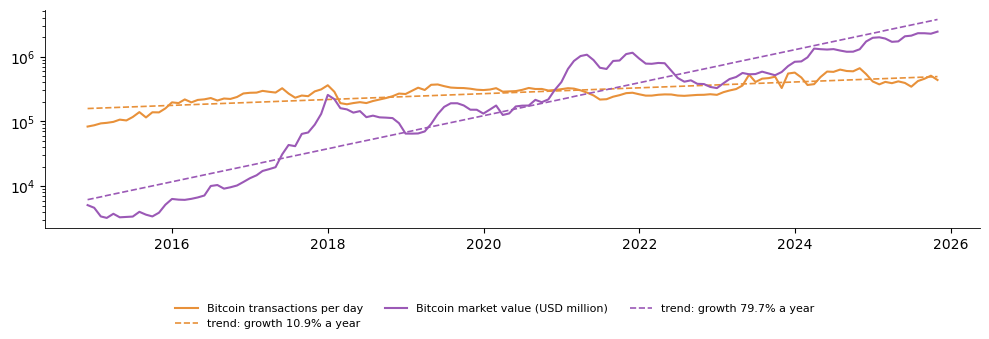

In [7]:
fig, ax = plt.subplots(figsize=(10, 3.4))
for (lab, (mth, fit)), col in zip(trend.items(), [BTC, ETH]):
    ax.plot(mth.index, mth.values, color=col, label=f'Bitcoin {lab}')
    ax.plot(mth.index, np.exp(fit.fittedvalues), color=col, ls='--', lw=1.2,
            label=f'trend: growth {100 * (np.exp(fit.params[1]) - 1):.1f}% a year')
ax.set_yscale('log')
slide_legend(fig, 0.2)
save_fig(fig, 'ba_l1_trend')

In [8]:
T = pd.DataFrame({lab: {'months': len(mth), 'g': fit.params[1], 'SE (Newey-West)': fit.bse[1], 'R2': fit.rsquared,
                        'annual growth exp(g)-1 (%)': 100 * (np.exp(fit.params[1]) - 1)}
                  for lab, (mth, fit) in trend.items()}).T
print(T.round(3).to_string())
both = pd.concat({k: v[0] for k, v in trend.items()}, axis=1).dropna()
tb = np.arange(len(both)) / 12
dfit = sm.OLS(np.log(both['market value (USD million)'] / both['transactions per day']).values,
              sm.add_constant(tb)).fit(cov_type='HAC', cov_kwds={'maxlags': 12})
print(f'\nDifference of the growth rates g_M - g_n: {dfit.params[1]:.3f} (Newey-West SE {dfit.bse[1]:.3f}), '
      f'z = {dfit.params[1] / dfit.bse[1]:.2f}')
print(f'First-order autocorrelation of the residuals of the difference regression: {sm.tsa.acf(dfit.resid, nlags=1)[1]:.2f}')

                            months      g  SE (Newey-West)     R2  annual growth exp(g)-1 (%)
transactions per day         132.0  0.104            0.021  0.617                      10.946
market value (USD million)   132.0  0.586            0.055  0.884                      79.723

Difference of the growth rates g_M - g_n: 0.482 (Newey-West SE 0.052), z = 9.28
First-order autocorrelation of the residuals of the difference regression: 0.96
